In [1]:
import sys, os
print(sys.executable)

/Users/andresho/Desktop/C-MARL/venv/bin/python3.11


In [2]:
import numpy as np
import time
from dataclasses import dataclass
import tensorflow as tf

In [3]:
import tensorflow as tf
tf.debugging.disable_traceback_filtering()

from tensorflow.keras import layers
a = layers.Input(shape=(4,))
b = layers.Input(shape=(4,))
x = layers.Concatenate()([a, b])

In [4]:
sys.path.insert(0, os.path.abspath("../.."))   # sandboxed/test2 → project root
from game_environments.ToyGame import ToyGame

from data_generation import *
from networks import *
from rollout import *
from agents import build_agents
from training import train

tf.random.set_seed(0)
np.random.seed(0)

cfg = ToyGame(128)
agents = build_agents(cfg, hidden=128)
belief_step = take_gru_step(agents)
print("TF", tf.__version__, "| Config:", cfg)

TF 2.14.0 | Config: <game_environments.ToyGame.ToyGame object at 0x141bac350>


In [5]:
hist = train(
    ToyGame, agents, belief_step, 
    B=200, n_iters=1000, log_every=100,
    team_interval=10
)

iter   100 | reward(adv) 0.491 | reward(clean) 0.499 | belief acc 0.755 | 26s
iter   200 | reward(adv) 0.450 | reward(clean) 0.506 | belief acc 0.757 | 52s
iter   300 | reward(adv) 0.546 | reward(clean) 0.493 | belief acc 0.738 | 78s
iter   400 | reward(adv) 0.552 | reward(clean) 0.493 | belief acc 0.733 | 104s
iter   500 | reward(adv) 0.683 | reward(clean) 0.546 | belief acc 0.860 | 130s
iter   600 | reward(adv) 0.218 | reward(clean) 0.490 | belief acc 0.823 | 155s
iter   700 | reward(adv) 0.596 | reward(clean) 0.515 | belief acc 0.601 | 181s
iter   800 | reward(adv) 0.776 | reward(clean) 0.753 | belief acc 0.781 | 206s
iter   900 | reward(adv) 0.990 | reward(clean) 0.987 | belief acc 0.760 | 232s
iter  1000 | reward(adv) 0.994 | reward(clean) 0.990 | belief acc 0.717 | 261s


In [6]:
record = run_episodes(ToyGame(1000), agents, belief_step)

In [7]:
print(record['reward'].shape)
total_reward = np.sum(record['reward'], axis=1)
avg_reward = np.mean(total_reward)
avg_reward2 = np.mean(record['reward'])
print(avg_reward)
print(avg_reward2)

(1000, 100)
99.14
0.9914


In [8]:
print(hist.keys())

dict_keys(['reward_adv', 'reward_clean', 'belief_acc'])


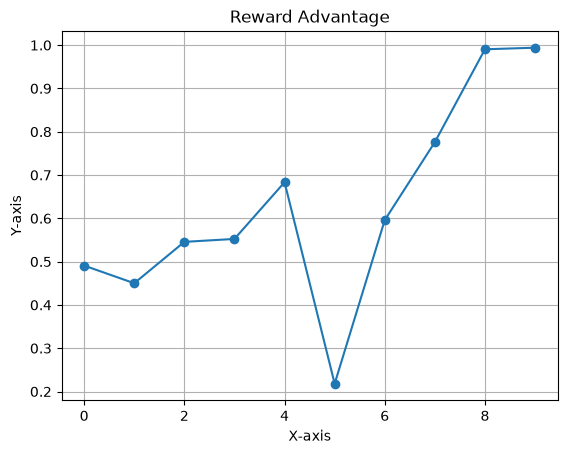

In [9]:
import matplotlib.pyplot as plt
plt.plot(range(len(hist['reward_adv'])),hist['reward_adv'], marker='o')

# Labels and title
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Reward Advantage")

# Optional: grid
plt.grid(True)

# Show plot
plt.show()

In [ ]:
from evaluation import *
w_before = agents.policy.get_weights()[0].copy()
eval_hist = evaluate_robustness(cfg, agents, belief_step, n_iters=2000, log_every=100)
w_after = agents.policy.get_weights()[0]
print("policy frozen:", np.allclose(w_before, w_after))

attack iter   100 | reward(adv) 0.006 | reward(clean) 0.992
attack iter   200 | reward(adv) 0.002 | reward(clean) 0.988
attack iter   300 | reward(adv) 0.002 | reward(clean) 0.990
attack iter   400 | reward(adv) 0.002 | reward(clean) 0.989
attack iter   500 | reward(adv) 0.004 | reward(clean) 0.991
attack iter   600 | reward(adv) 0.001 | reward(clean) 0.989
attack iter   700 | reward(adv) 0.001 | reward(clean) 0.990
attack iter   800 | reward(adv) 0.002 | reward(clean) 0.990
attack iter   900 | reward(adv) 0.002 | reward(clean) 0.991
attack iter  1000 | reward(adv) 0.002 | reward(clean) 0.991
attack iter  1100 | reward(adv) 0.002 | reward(clean) 0.990
attack iter  1200 | reward(adv) 0.001 | reward(clean) 0.992
attack iter  1300 | reward(adv) 0.002 | reward(clean) 0.990
attack iter  1400 | reward(adv) 0.002 | reward(clean) 0.991
attack iter  1500 | reward(adv) 0.002 | reward(clean) 0.991
attack iter  1600 | reward(adv) 0.002 | reward(clean) 0.990
attack iter  1700 | reward(adv) 0.002 | 

In [ ]:
eval_hist.keys()

In [ ]:
plt.plot(range(len(eval_hist['curve'])),eval_hist['curve'], marker='o')

# Labels and title
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Reward Advantage")

# Optional: grid
plt.grid(True)

# Show plot
plt.show()

In [ ]:
# and: what does the trained team get on clean episodes, right now?
ev = run_episodes(cfg, agents, belief_step)
ep_r = ev['reward'].mean(axis=1)
clean = ep_r[ev['theta'][:,0,:].sum(axis=1)==0].mean()
print("clean reward with trained agents:", clean)   # should be ~0.99